In [18]:
# ==============================================================================
# CELL 1: Imports and Setup
# ==============================================================================
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random
import pickle
import torch

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from dataset_skin import get_federated_dataloaders
from models_skin import get_resnet18_classifier
from utils_skin import calculate_entropy, compute_dynamic_mu, evaluate_resnet
from client_skin import train_client_resnet_dp
from client_skin import train_client_resnet_nodp
from server_skin import federated_averaging

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device Name: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"PyTorch Version: {torch.__version__}")

CUDA Available: True
Device Name: NVIDIA GeForce RTX 3050 Laptop GPU
PyTorch Version: 2.6.0+cu124


In [20]:
def set_seed(seed=42):
    """Locks all random number generators for exact reproducibility."""
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [21]:
# Lock the universe to Seed 42
set_seed(42)

In [22]:
# # ==============================================================================
# # CELL 2: Data Loading & Hybrid Weight Calculation (alpha = 0.1)
# # ==============================================================================
# num_clients = 5
# # UPDATED: alpha=0.1 forces extreme Non-IID distribution
# client_loaders, test_loader = get_federated_dataloaders(num_clients=num_clients, alpha=0.1, batch_size=32)

# class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

# entropies = []
# clinic_distributions = []
# sample_counts = [] 

# for i, loader in enumerate(client_loaders):
#     labels = torch.cat([y for _, y in loader]).squeeze().numpy()
#     entropies.append(calculate_entropy(labels, num_classes=7))
    
#     counts = np.bincount(labels, minlength=7)
#     clinic_distributions.append(counts)
#     sample_counts.append(len(labels)) 

# dynamic_mus = compute_dynamic_mu(entropies, num_classes=7, mu_base=0.01, lambda_scale=1.5)

# # Calculate the Hybrid FedShield Weights (Entropy * Sample Size)
# fedshield_weights = [e * n for e, n in zip(entropies, sample_counts)]

# # Display Formatted Matrix
# df_dist = pd.DataFrame(clinic_distributions, columns=[f"{c} (Class {idx})" for idx, c in enumerate(class_names)])
# df_dist.insert(0, "Clinic", [f"Clinic {i+1}" for i in range(num_clients)])
# df_dist["Total Samples"] = sample_counts
# df_dist["Entropy (H_k)"] = [f"{h:.4f}" for h in entropies]
# df_dist["Assigned mu_k"] = [f"{m:.4f}" for m in dynamic_mus]
# df_dist["Hybrid Weight"] = [f"{w:.2f}" for w in fedshield_weights] 

# print("\n========================= CLINIC CLASS DISTRIBUTION MATRIX =========================")
# print(df_dist.to_string(index=False))
# print("====================================================================================\n")

# Exponential Hybrid Weighting
num_clients = 5
client_loaders, test_loader = get_federated_dataloaders(num_clients=num_clients, alpha=0.1, batch_size=32)

class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

entropies = []
clinic_distributions = []
sample_counts = [] 

for i, loader in enumerate(client_loaders):
    labels = torch.cat([y for _, y in loader]).squeeze().numpy()
    entropies.append(calculate_entropy(labels, num_classes=7))
    
    counts = np.bincount(labels, minlength=7)
    clinic_distributions.append(counts)
    sample_counts.append(len(labels)) 

# FIX 1: Lower lambda_scale from 1.5 to 0.5 to prevent paralyzing skewed clinics
dynamic_mus = compute_dynamic_mu(entropies, num_classes=7, mu_base=0.01, lambda_scale=0.5)

# FIX 2: Exponential Hybrid Weights (N_k * e^(H_k))
# fedshield_weights = [n * np.exp(e) for e, n in zip(entropies, sample_counts)]
# THE FINAL FIX: Sub-linear (Square-Root) Volume Scaling 
# fedshield_weights = [np.sqrt(n) * np.exp(e) for e, n in zip(entropies, sample_counts)]
# THE FINAL ARCHITECTURE: Pure Exponential Entropy Weighting
fedshield_weights = [np.exp(e) for e in entropies]

# Display Formatted Matrix
df_dist = pd.DataFrame(clinic_distributions, columns=[f"{c} (Class {idx})" for idx, c in enumerate(class_names)])
df_dist.insert(0, "Clinic", [f"Clinic {i+1}" for i in range(num_clients)])
df_dist["Total Samples"] = sample_counts
df_dist["Entropy (H_k)"] = [f"{h:.4f}" for h in entropies]
df_dist["Assigned mu_k"] = [f"{m:.4f}" for m in dynamic_mus]
df_dist["Exp Hybrid Weight"] = [f"{w:.2f}" for w in fedshield_weights] 

print("\n========================= CLINIC CLASS DISTRIBUTION MATRIX =========================")
print(df_dist.to_string(index=False))
print("====================================================================================\n")

Downloading/Loading DermaMNIST dataset...
Data Partitioning Complete across 5 Virtual Clinics.

========================= CLINIC CLASS DISTRIBUTION MATRIX =========================
  Clinic  akiec (Class 0)  bcc (Class 1)  bkl (Class 2)  df (Class 3)  mel (Class 4)  nv (Class 5)  vasc (Class 6)  Total Samples Entropy (H_k) Assigned mu_k Exp Hybrid Weight
Clinic 1                0            347              0             0             27            17              46            437        1.0364        0.0189              2.82
Clinic 2                1              0              0             0            189             0              52            242        0.7879        0.0201              2.20
Clinic 3                0             11            670            73            463             0               0           1217        1.3094        0.0175              3.70
Clinic 4              226              0              1             6             99             0               1 

In [23]:
# ==============================================================================
# CELL 3: DP Training Function
# ==============================================================================
'''
def run_resnet_experiment(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING PHASE 2: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_eps = 0.0

    for round_num in range(num_rounds):
        client_models = []
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, eps = train_client_resnet_dp(
                local_model=local_model,
                global_model=global_model,
                train_loader=client_loaders[i],
                mu=current_mu,
                device=device,
                epochs=2, 
                lr=0.1, 
                noise_multiplier=1.2,
                max_grad_norm=1.0
            )
            client_models.append(trained_model)
            final_eps = eps

        # Server Aggregation
        if algorithm_name == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
        
        acc, auc = evaluate_resnet(global_model, test_loader, device)
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"Final {algorithm_name} AUC: {auc_history[-1]:.4f} | Epsilon: {final_eps:.2f}")
    return auc_history, global_model
'''
def run_resnet_experiment(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING PHASE 2: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_eps = 0.0
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, eps = train_client_resnet_dp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1, 
                noise_multiplier=1.2, max_grad_norm=1.0
            )
            client_models.append(trained_model)
            final_eps = eps

        if algorithm_name == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
        
        # Grab predictions only on the final round
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal {algorithm_name} AUC: {auc_history[-1]:.4f} | Epsilon: {final_eps:.2f}")
    
    # NEW: Print full 7-class report and plot the 7x7 matrix
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} DP Confusion Matrix")
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model


========== STARTING PHASE 2: FedAvg ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 01/15 | Global Test AUC: 0.5680 | Accuracy: 0.3980


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 02/15 | Global Test AUC: 0.5830 | Accuracy: 0.1855


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


... (21 outputs left out)

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 14/15 | Global Test AUC: 0.6346 | Accuracy: 0.3576


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 15/15 | Global Test AUC: 0.6251 | Accuracy: 0.4504

Final FedAvg AUC: 0.6251 | Epsilon: 0.47

--- FedAvg (DP) Classification Report ---
              precision    recall  f1-score   support

       akiec     0.1348    0.1818    0.1548        66
         bcc     0.1463    0.1748    0.1593       103
         bkl     0.3256    0.3182    0.3218       220
          df     0.0000    0.0000    0.0000        23
         mel     0.2420    0.3722    0.2933       223
          nv     0.8594    0.5287    0.6547      1341
        vasc     0.0304    0.3793    0.0563        29

    accuracy                         0.4504      2005
   macro avg     0.2484    0.2793    0.2343      2005
weighted avg     0.6498    0.4504    0.5199      2005



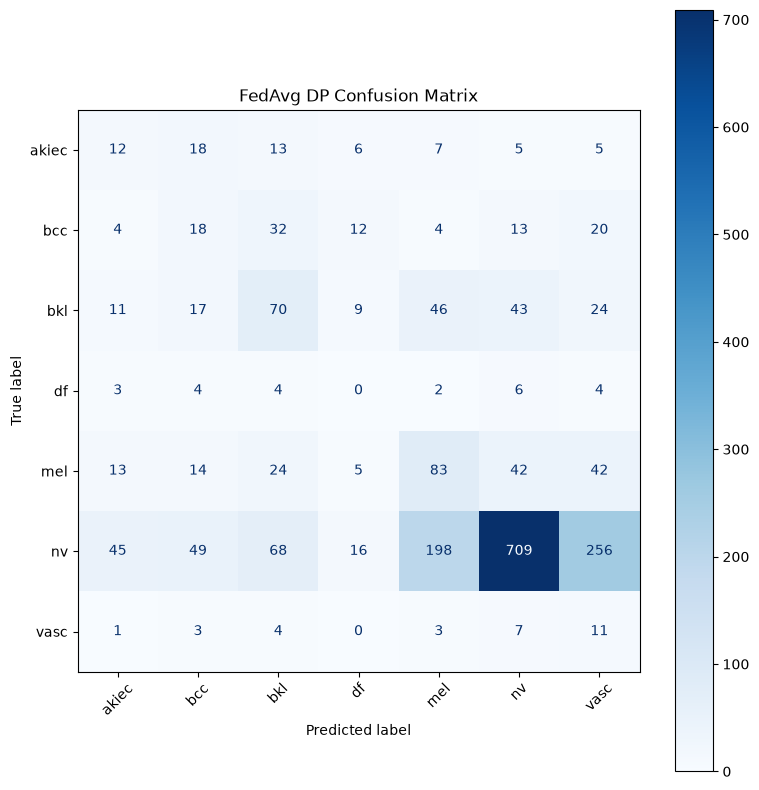

In [24]:
# ==============================================================================
# CELL 4: Run DP Experiments & Plot
# ==============================================================================
auc_fedavg, _ = run_resnet_experiment("FedAvg", num_rounds=15)


========== STARTING PHASE 2: FedProx ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 01/15 | Global Test AUC: 0.5293 | Accuracy: 0.5915


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 02/15 | Global Test AUC: 0.5732 | Accuracy: 0.1077


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


... (21 outputs left out)

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 14/15 | Global Test AUC: 0.6376 | Accuracy: 0.3970


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 15/15 | Global Test AUC: 0.6472 | Accuracy: 0.2878

Final FedProx AUC: 0.6472 | Epsilon: 0.47

--- FedProx (DP) Classification Report ---
              precision    recall  f1-score   support

       akiec     0.1272    0.3333    0.1841        66
         bcc     0.1000    0.0388    0.0559       103
         bkl     0.2715    0.1864    0.2210       220
          df     0.0556    0.0870    0.0678        23
         mel     0.1548    0.7534    0.2569       223
          nv     0.8204    0.2521    0.3856      1341
        vasc     0.0185    0.0690    0.0292        29

    accuracy                         0.2878      2005
   macro avg     0.2211    0.2457    0.1715      2005
weighted avg     0.6059    0.2878    0.3209      2005



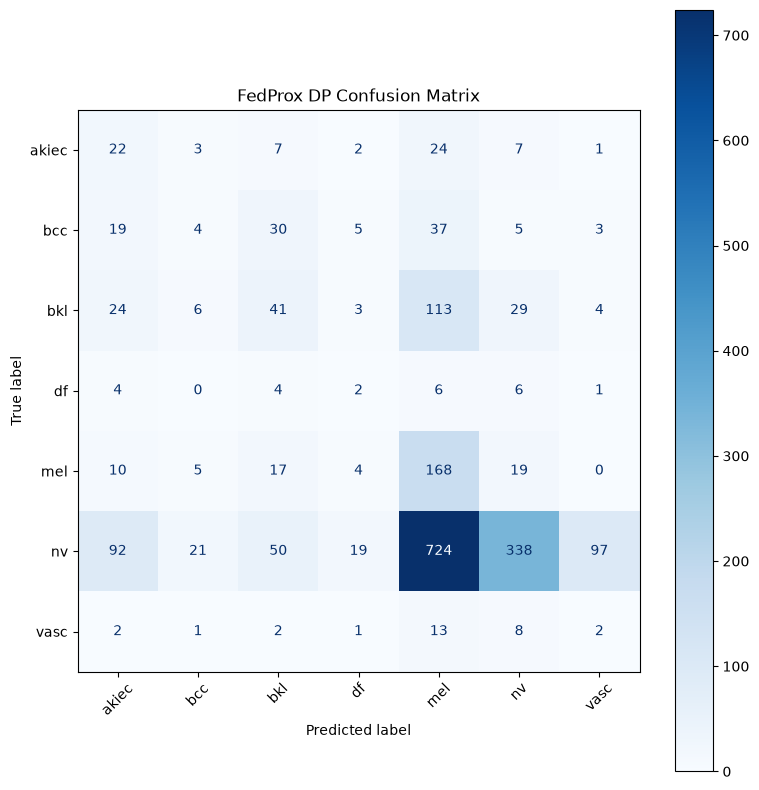

In [25]:
auc_fedprox, _ = run_resnet_experiment("FedProx", num_rounds=15)


========== STARTING PHASE 2: FedShield ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 01/15 | Global Test AUC: 0.5877 | Accuracy: 0.1342


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 02/15 | Global Test AUC: 0.6199 | Accuracy: 0.3606


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


... (21 outputs left out)

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 14/15 | Global Test AUC: 0.6688 | Accuracy: 0.2589


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


Round 15/15 | Global Test AUC: 0.6689 | Accuracy: 0.3995

Final FedShield AUC: 0.6689 | Epsilon: 0.47

--- FedShield (DP) Classification Report ---
              precision    recall  f1-score   support

       akiec     0.1758    0.2424    0.2038        66
         bcc     0.1760    0.2136    0.1930       103
         bkl     0.2185    0.2364    0.2271       220
          df     0.0222    0.0435    0.0294        23
         mel     0.2228    0.5336    0.3144       223
          nv     0.8942    0.4348    0.5850      1341
        vasc     0.0250    0.2759    0.0458        29

    accuracy                         0.3995      2005
   macro avg     0.2478    0.2829    0.2284      2005
weighted avg     0.6623    0.3995    0.4688      2005



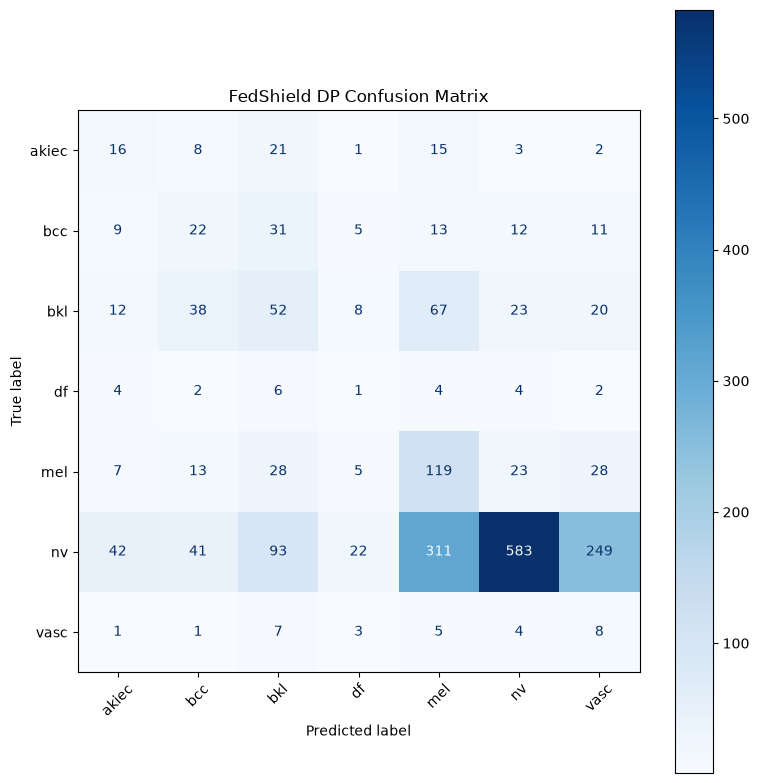

In [26]:
auc_fedshield, final_model = run_resnet_experiment("FedShield", num_rounds=15)

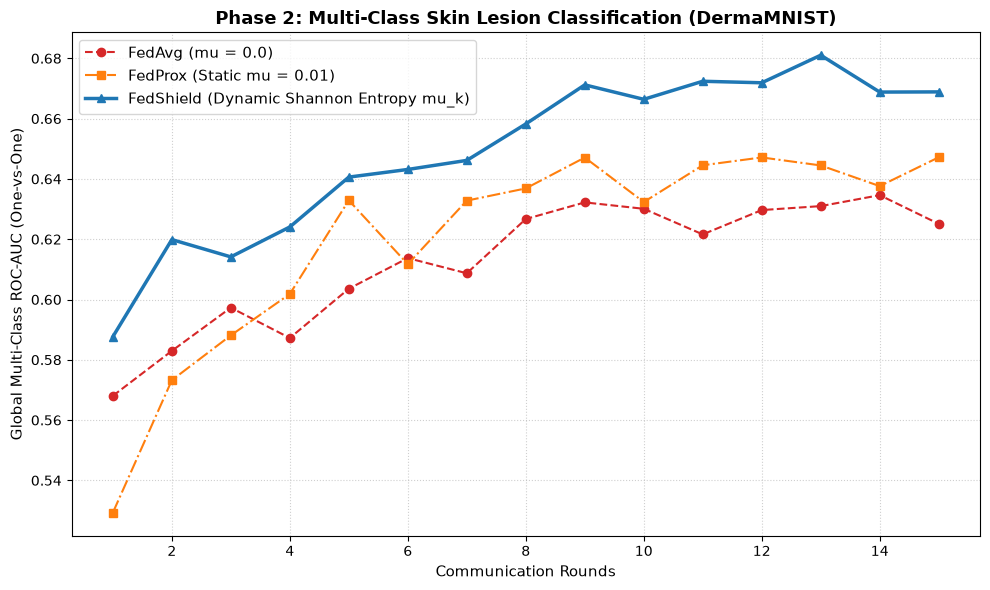

In [27]:
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (mu = 0.0)')
plt.plot(rounds_range, auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (Static mu = 0.01)')
plt.plot(rounds_range, auc_fedshield, marker='^', linestyle='-', color='tab:blue', linewidth=2.5, label='FedShield (Dynamic Shannon Entropy mu_k)')

plt.title("Phase 2: Multi-Class Skin Lesion Classification (DermaMNIST)", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [28]:
torch.save(final_model.state_dict(), "fedshield_resnet18_dermamnist_2.pth")
print("Trained FedShield Global Model successfully saved to 'fedshield_resnet18_dermamnist_2.pth'")

Trained FedShield Global Model successfully saved to 'fedshield_resnet18_dermamnist_2.pth'


In [29]:
# ==============================================================================
# CELL 5: Non-DP Training Function (Ablation Study)
# ==============================================================================
'''
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []

    for round_num in range(num_rounds):
        client_models = []
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model,
                global_model=global_model,
                train_loader=client_loaders[i],
                mu=current_mu,
                device=device,
                epochs=2, 
                lr=0.1
            )
            client_models.append(trained_model)

        # UPDATED: No Server-Side Entropy for Non-DP Ablation.
        global_model = federated_averaging(global_model, client_models, weights=None)
        
        acc, auc = evaluate_resnet(global_model, test_loader, device)
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"Final Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    return auc_history, global_model
    '''
"""
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name == "FedShield":
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1
            )
            client_models.append(trained_model)

        global_model = federated_averaging(global_model, client_models, weights=None)
        
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    
    # NEW: Print full 7-class report and plot the 7x7 matrix
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (No-DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Greens, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} No-DP Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model
"""
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=7, freeze_backbone=True).to(device)
    auc_history = []
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            elif algorithm_name in ["FedShield_Local", "FedShield_Full"]:
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1
            )
            client_models.append(trained_model)

        # NEW: Apply Server weights ONLY for FedShield_Full
        if algorithm_name == "FedShield_Full":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
        
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    
    class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    print(f"\n--- {algorithm_name} (No-DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Greens, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} No-DP Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model

Starting Non-DP Ablation Study...

========== STARTING NON-DP PHASE: FedAvg ==========
Round 01/15 | Global Test AUC: 0.6108 | Accuracy: 0.1112
Round 02/15 | Global Test AUC: 0.7899 | Accuracy: 0.6534
Round 03/15 | Global Test AUC: 0.6467 | Accuracy: 0.1192
Round 04/15 | Global Test AUC: 0.6664 | Accuracy: 0.1107
Round 05/15 | Global Test AUC: 0.6157 | Accuracy: 0.1112
Round 06/15 | Global Test AUC: 0.7369 | Accuracy: 0.6524
Round 07/15 | Global Test AUC: 0.6970 | Accuracy: 0.1297
Round 08/15 | Global Test AUC: 0.7109 | Accuracy: 0.1112
Round 09/15 | Global Test AUC: 0.6459 | Accuracy: 0.1247
Round 10/15 | Global Test AUC: 0.7555 | Accuracy: 0.5985
Round 11/15 | Global Test AUC: 0.6426 | Accuracy: 0.1192
Round 12/15 | Global Test AUC: 0.6607 | Accuracy: 0.1197
Round 13/15 | Global Test AUC: 0.6793 | Accuracy: 0.1202
Round 14/15 | Global Test AUC: 0.7449 | Accuracy: 0.5591
Round 15/15 | Global Test AUC: 0.6377 | Accuracy: 0.1187

Final Non-DP FedAvg AUC: 0.6377

--- FedAvg (No-DP) Class

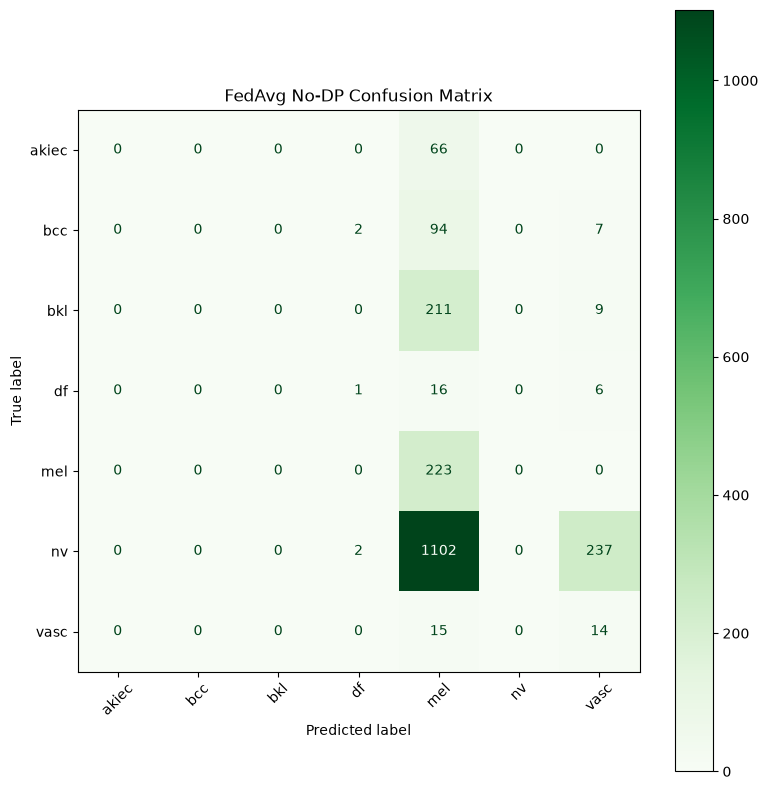

In [30]:
# ==============================================================================
# CELL 6: Run Non-DP Experiments
# ==============================================================================
print("Starting Non-DP Ablation Study...")
nodp_auc_fedavg, nodp_model_fedavg = run_resnet_experiment_nodp("FedAvg", num_rounds=15)



========== STARTING NON-DP PHASE: FedProx ==========
Round 01/15 | Global Test AUC: 0.6317 | Accuracy: 0.1112
Round 02/15 | Global Test AUC: 0.6753 | Accuracy: 0.1287
Round 03/15 | Global Test AUC: 0.8029 | Accuracy: 0.3796
Round 04/15 | Global Test AUC: 0.6884 | Accuracy: 0.1651
Round 05/15 | Global Test AUC: 0.7732 | Accuracy: 0.1471
Round 06/15 | Global Test AUC: 0.7870 | Accuracy: 0.2394
Round 07/15 | Global Test AUC: 0.7438 | Accuracy: 0.1810
Round 08/15 | Global Test AUC: 0.7952 | Accuracy: 0.5561
Round 09/15 | Global Test AUC: 0.7890 | Accuracy: 0.1506
Round 10/15 | Global Test AUC: 0.7511 | Accuracy: 0.1546
Round 11/15 | Global Test AUC: 0.7649 | Accuracy: 0.3970
Round 12/15 | Global Test AUC: 0.7968 | Accuracy: 0.2229
Round 13/15 | Global Test AUC: 0.8013 | Accuracy: 0.2254
Round 14/15 | Global Test AUC: 0.7830 | Accuracy: 0.4908
Round 15/15 | Global Test AUC: 0.7668 | Accuracy: 0.1835

Final Non-DP FedProx AUC: 0.7668

--- FedProx (No-DP) Classification Report ---
          

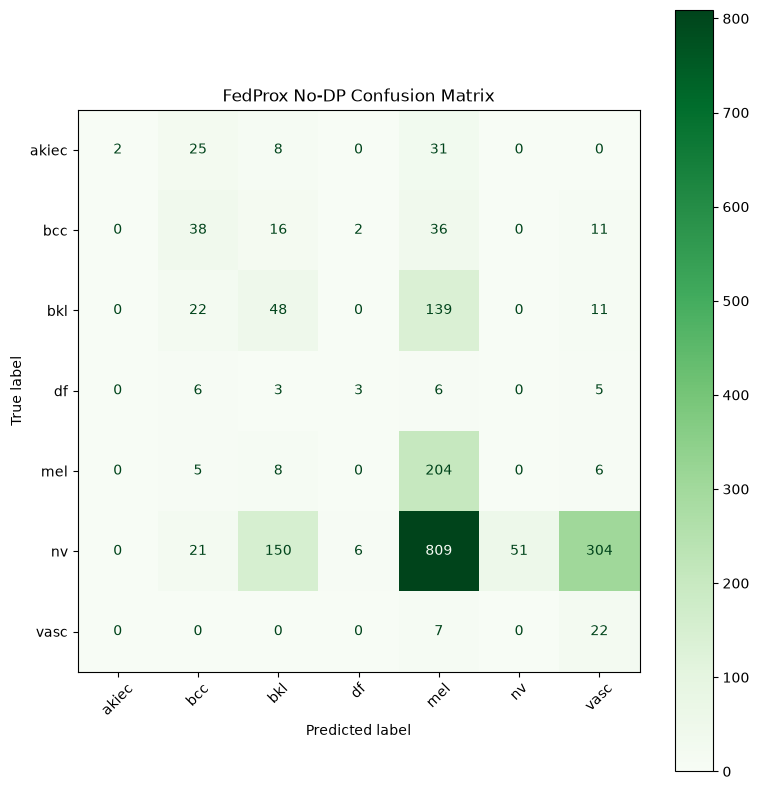

In [31]:
nodp_auc_fedprox, nodp_model_fedprox = run_resnet_experiment_nodp("FedProx", num_rounds=15)



========== STARTING NON-DP PHASE: FedShield_Local ==========
Round 01/15 | Global Test AUC: 0.6280 | Accuracy: 0.1142
Round 02/15 | Global Test AUC: 0.7183 | Accuracy: 0.1586
Round 03/15 | Global Test AUC: 0.7378 | Accuracy: 0.1436
Round 04/15 | Global Test AUC: 0.8107 | Accuracy: 0.4673
Round 05/15 | Global Test AUC: 0.7342 | Accuracy: 0.1337
Round 06/15 | Global Test AUC: 0.7857 | Accuracy: 0.5262
Round 07/15 | Global Test AUC: 0.7368 | Accuracy: 0.1222
Round 08/15 | Global Test AUC: 0.7856 | Accuracy: 0.4549
Round 09/15 | Global Test AUC: 0.7062 | Accuracy: 0.1711
Round 10/15 | Global Test AUC: 0.7819 | Accuracy: 0.3466
Round 11/15 | Global Test AUC: 0.8039 | Accuracy: 0.3536
Round 12/15 | Global Test AUC: 0.7655 | Accuracy: 0.3741
Round 13/15 | Global Test AUC: 0.7810 | Accuracy: 0.2414
Round 14/15 | Global Test AUC: 0.8004 | Accuracy: 0.4998
Round 15/15 | Global Test AUC: 0.7902 | Accuracy: 0.1810

Final Non-DP FedShield_Local AUC: 0.7902

--- FedShield_Local (No-DP) Classificati

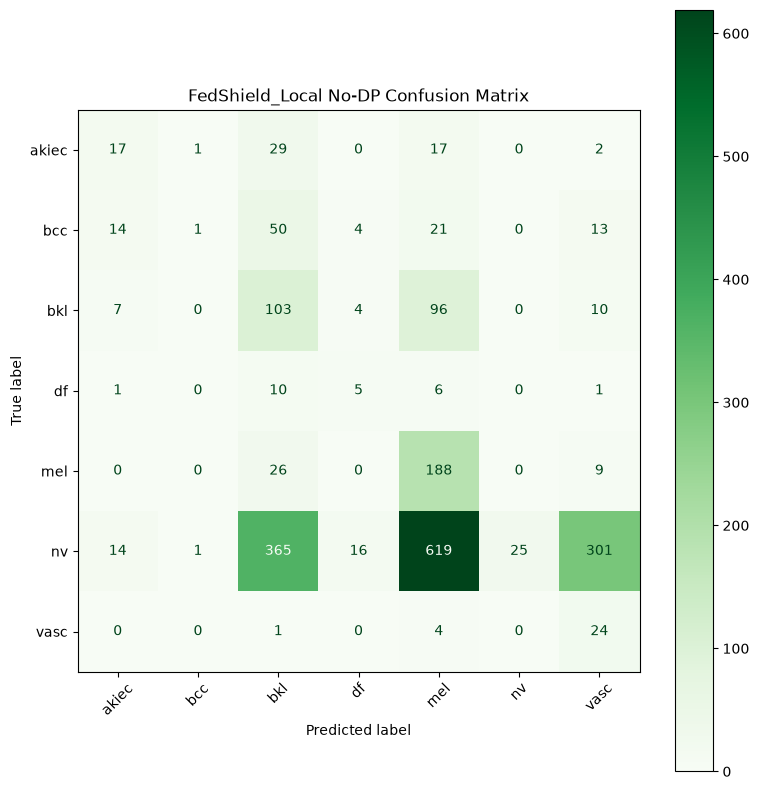

In [32]:
nodp_auc_fedshield_local, nodp_model_fedshield_local = run_resnet_experiment_nodp("FedShield_Local", num_rounds=15)


========== STARTING NON-DP PHASE: FedShield_Full ==========
Round 01/15 | Global Test AUC: 0.6410 | Accuracy: 0.1112
Round 02/15 | Global Test AUC: 0.7705 | Accuracy: 0.1277
Round 03/15 | Global Test AUC: 0.7641 | Accuracy: 0.1122
Round 04/15 | Global Test AUC: 0.7351 | Accuracy: 0.1152
Round 05/15 | Global Test AUC: 0.7619 | Accuracy: 0.3586
Round 06/15 | Global Test AUC: 0.7454 | Accuracy: 0.3845
Round 07/15 | Global Test AUC: 0.7959 | Accuracy: 0.3855
Round 08/15 | Global Test AUC: 0.7768 | Accuracy: 0.3102
Round 09/15 | Global Test AUC: 0.7461 | Accuracy: 0.1776
Round 10/15 | Global Test AUC: 0.8001 | Accuracy: 0.4269
Round 11/15 | Global Test AUC: 0.7994 | Accuracy: 0.1845
Round 12/15 | Global Test AUC: 0.7786 | Accuracy: 0.4828
Round 13/15 | Global Test AUC: 0.8035 | Accuracy: 0.2584
Round 14/15 | Global Test AUC: 0.7972 | Accuracy: 0.4414
Round 15/15 | Global Test AUC: 0.7851 | Accuracy: 0.2514

Final Non-DP FedShield_Full AUC: 0.7851

--- FedShield_Full (No-DP) Classification 

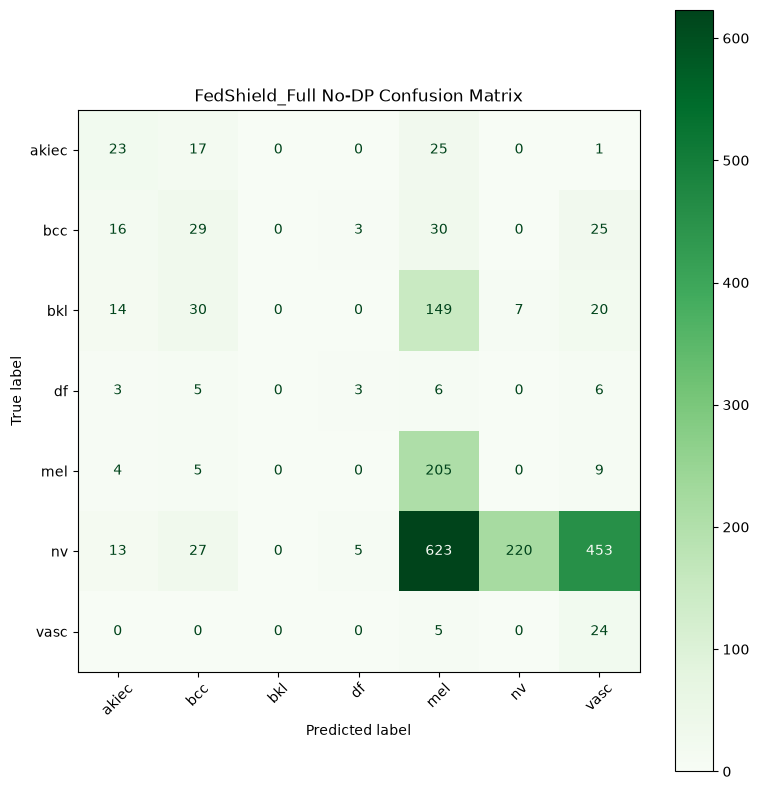

In [33]:
nodp_auc_fedshield_full, nodp_model_fedshield_full = run_resnet_experiment_nodp("FedShield_Full", num_rounds=15)

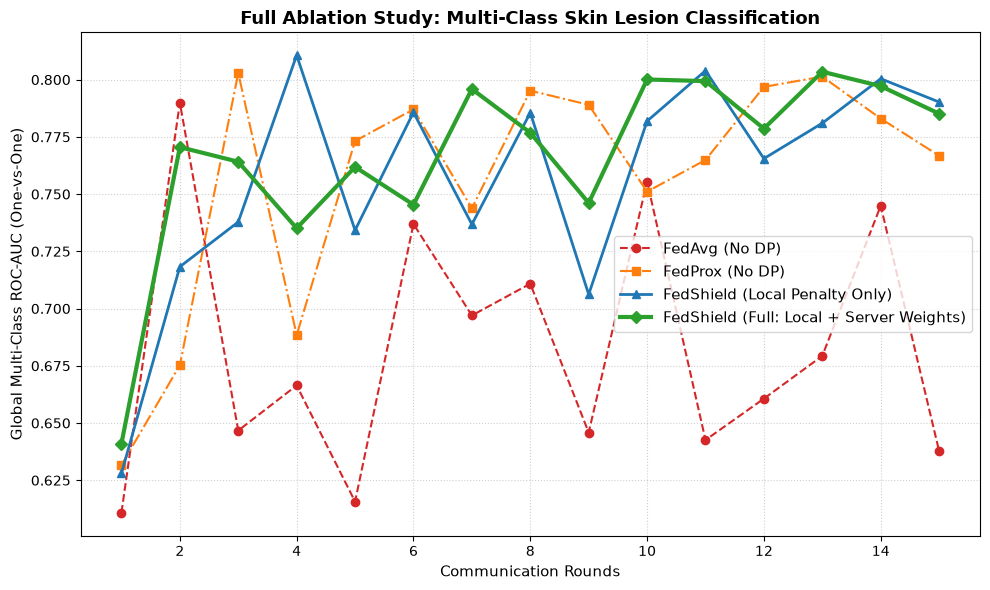

In [34]:
# ==============================================================================
# CELL 7: Plot Non-DP Ablation Study Results
# ==============================================================================
# Plot the 4-step Ablation Study
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, nodp_auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (No DP)')
plt.plot(rounds_range, nodp_auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (No DP)')
plt.plot(rounds_range, nodp_auc_fedshield_local, marker='^', linestyle='-', color='tab:blue', linewidth=2, label='FedShield (Local Penalty Only)')
plt.plot(rounds_range, nodp_auc_fedshield_full, marker='D', linestyle='-', color='tab:green', linewidth=3, label='FedShield (Full: Local + Server Weights)')

plt.title("Full Ablation Study: Multi-Class Skin Lesion Classification", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [35]:
"""
# 1. Bundle EVERYTHING (DP and Non-DP histories) into one master dictionary
full_context = {
    # DP Data
    "auc_fedshield": auc_fedshield,
    "auc_fedprox": auc_fedprox,
    "auc_fedavg": auc_fedavg,
    "entropies": entropies,
    "dynamic_mus": dynamic_mus,
    "fedshield_weights": fedshield_weights,
    "clinic_distributions": clinic_distributions,
    "sample_counts": sample_counts,
    
    # Non-DP Data
    "nodp_auc_fedavg": nodp_auc_fedavg,
    "nodp_auc_fedprox": nodp_auc_fedprox,
    "nodp_auc_fedshield": nodp_auc_fedshield
}

# 2. Save all the variables to a pickle file
with open("full_experiment_checkpoint_2.pkl", "wb") as f:
    pickle.dump(full_context, f)

# 3. Save ALL the trained model weights
torch.save(final_model.state_dict(), "fedshield_dp_model_2.pth")
torch.save(nodp_model_fedavg.state_dict(), "nodp_fedavg_model_2.pth")
torch.save(nodp_model_fedprox.state_dict(), "nodp_fedprox_model_2.pth")
torch.save(nodp_model_fedshield.state_dict(), "nodp_fedshield_model_2.pth")

print("✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.")
"""
# 1. Bundle EVERYTHING (DP and Non-DP histories) into one master dictionary
full_context = {
    # DP Data
    "auc_fedshield": auc_fedshield,
    "auc_fedprox": auc_fedprox,
    "auc_fedavg": auc_fedavg,
    "entropies": entropies,
    "dynamic_mus": dynamic_mus,
    "fedshield_weights": fedshield_weights,
    "clinic_distributions": clinic_distributions,
    "sample_counts": sample_counts,
    
    # Non-DP Data (Updated for 4-step Ablation)
    "nodp_auc_fedavg": nodp_auc_fedavg,
    "nodp_auc_fedprox": nodp_auc_fedprox,
    "nodp_auc_fedshield_local": nodp_auc_fedshield_local,
    "nodp_auc_fedshield_full": nodp_auc_fedshield_full
}

# 2. Save all the variables to a pickle file
with open("full_experiment_checkpoint_2.pkl", "wb") as f:
    pickle.dump(full_context, f)

# 3. Save ALL the trained model weights
torch.save(final_model.state_dict(), "fedshield_dp_model_2.pth")
torch.save(nodp_model_fedavg.state_dict(), "nodp_fedavg_model_2.pth")
torch.save(nodp_model_fedprox.state_dict(), "nodp_fedprox_model_2.pth")
torch.save(nodp_model_fedshield_local.state_dict(), "nodp_fedshield_local_model_2.pth")
torch.save(nodp_model_fedshield_full.state_dict(), "nodp_fedshield_full_model_2.pth")

print("✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.")

✅ ENTIRE kernel state and all models successfully saved! You can now close the notebook.
